# A global surrogate in one picture

A court uses an opaque model that predicts the risk that a defendant is rearrested within two
years. To draw the idea of a surrogate, this notebook uses a version of the model with **one
feature, the age**. Then the whole model is one curve.

The recipe for a global surrogate:

1. Select inputs (the training data, or other data from the same distribution).
2. Ask the opaque model `f` for its prediction for each input.
3. Train an interpretable model `g` on these predictions.
4. Read `g`, and measure how well it fits `f`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from recidivism_data import load_xy
from recidivism_data.shared import age_model, new_gbm
from recidivism_data.theme import BLUE, INK, INK2, ORANGE, use_theme
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeRegressor, plot_tree

warnings.filterwarnings("ignore")
use_theme()

X_train, y_train = load_xy("train")
X_test, _ = load_xy("test")
f, risk = age_model()  # 150 boosted trees, with age as the only feature

## A linear surrogate, trained on 8 samples

The light blue dots are the training data (the share of people of each age who were
rearrested). The blue line is the opaque model. The orange dots are 8 inputs for which we ask
the model; the dashed line is a linear regression on these 8 answers.

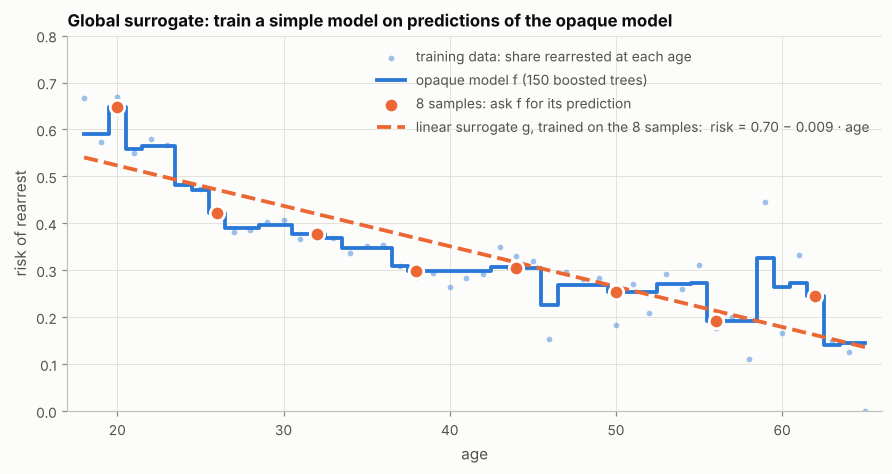

R² of the surrogate against the opaque model, on the test people: 0.72


In [2]:
samples = np.linspace(20, 62, 8)  # 1. select inputs
answers = risk(samples)  # 2. ask the opaque model
g = LinearRegression().fit(samples.reshape(-1, 1), answers)  # 3. train the interpretable model

ages = np.arange(18, 66.0)
rate = y_train.groupby(X_train["age"]).mean().loc[18:65]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(
    rate.index,
    rate,
    s=14,
    color=BLUE,
    alpha=0.45,
    linewidth=0,
    label="training data: share rearrested at each age",
)
ax.step(
    ages,
    risk(ages),
    where="mid",
    color=BLUE,
    linewidth=2.5,
    label="opaque model f (150 boosted trees)",
)
ax.scatter(
    samples,
    answers,
    s=90,
    color=ORANGE,
    edgecolor="white",
    linewidth=1.8,
    zorder=4,
    label="8 samples: ask f for its prediction",
)
label = f"linear surrogate g, trained on the 8 samples:  risk = {g.intercept_:.2f} − {-g.coef_[0]:.3f} · age"
ax.plot(
    ages, g.predict(ages.reshape(-1, 1)), color=ORANGE, linewidth=2.5, linestyle="--", label=label
)
ax.set(xlabel="age", ylabel="risk of rearrest", xlim=(17, 66), ylim=(0, 0.8))
ax.set_title("Global surrogate: train a simple model on predictions of the opaque model")
ax.legend(loc="upper right", labelcolor=INK2)
plt.show()

test_ages = X_test["age"].to_numpy(float)
fidelity = r2_score(
    risk(test_ages), g.predict(test_ages.reshape(-1, 1))
)  # 4. how well does g fit f?
print(f"R² of the surrogate against the opaque model, on the test people: {fidelity:.2f}")

The surrogate is one sentence: "the risk decreases by about 0.09 for each 10 years of age".
That is a useful summary and it is wrong in the details: the opaque model decreases quickly
to the age of 27 and slowly after that, so the line is too low for the young and for the old.

## A tree surrogate, with two features

With `age` and `priors_count` the opaque model is a surface. A tree with 6 leaves, trained on
the predictions of the model, divides the surface into 6 rectangles.

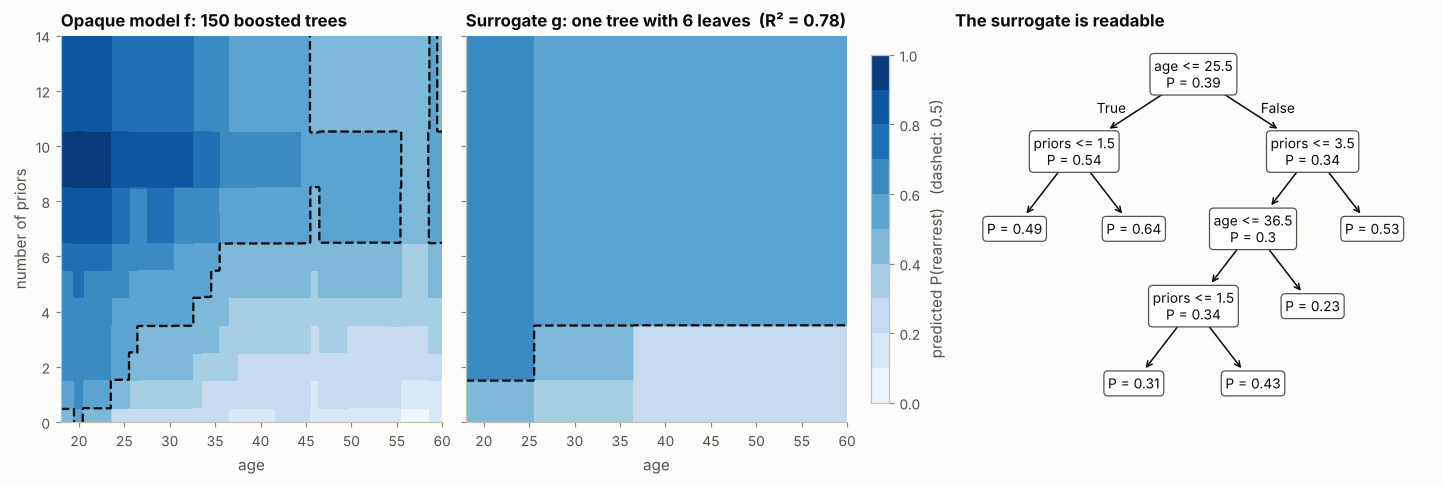

In [3]:
two = ["age", "priors_count"]
f2 = new_gbm().fit(X_train[two].astype(float), y_train)


def risk2(X: pd.DataFrame) -> np.ndarray:
    return f2.predict_proba(X[two].astype(float))[:, 1]


g2 = DecisionTreeRegressor(max_leaf_nodes=6, random_state=0).fit(
    X_train[two].astype(float), risk2(X_train)
)
fidelity2 = r2_score(risk2(X_test), g2.predict(X_test[two].astype(float)))

age, priors = np.meshgrid(np.linspace(18, 60, 300), np.linspace(0, 14, 300))
grid = pd.DataFrame({"age": age.ravel(), "priors_count": priors.ravel()})
surfaces = [risk2(grid).reshape(age.shape), g2.predict(grid).reshape(age.shape)]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), width_ratios=[1, 1, 1.25])
titles = [
    "Opaque model f: 150 boosted trees",
    f"Surrogate g: one tree with 6 leaves  (R² = {fidelity2:.2f})",
]
for ax, surface, title in zip(axes, surfaces, titles):
    filled = ax.contourf(age, priors, surface, levels=np.linspace(0, 1, 11), cmap="Blues")
    ax.contour(age, priors, surface, levels=[0.5], colors=INK, linewidths=1.5, linestyles="--")
    ax.set(title=title, xlabel="age", xlim=(18, 60), ylim=(0, 14))
    ax.grid(visible=False)
axes[0].set_ylabel("number of priors")
axes[1].set_yticklabels([])
fig.colorbar(
    filled, ax=axes[:2], label="predicted P(rearrest)   (dashed: 0.5)", shrink=0.9, pad=0.02
)

plot_tree(
    g2,
    feature_names=["age", "priors"],
    impurity=False,
    rounded=True,
    precision=2,
    fontsize=9,
    ax=axes[2],
)
for text in axes[2].texts:
    lines = [line for line in text.get_text().split("\n") if not line.startswith("samples")]
    text.set_text("\n".join(lines).replace("value = ", "P = "))
    if text.get_bbox_patch() is not None:
        text.get_bbox_patch().set(facecolor="white", edgecolor=INK2, linewidth=0.8)
axes[2].set_title("The surrogate is readable")
axes[2].grid(visible=False)
plt.show()

`surrogate.py` in this folder does the same for the model with all features, and shows where
such a surrogate is not truthful.